<a href="https://colab.research.google.com/github/snehaltaori/data-mining-assignment-2/blob/main/submissions/Data_Mining_Recommender_System.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
!pip install pandas numpy scipy scikit-learn pyarrow matplotlib seaborn

In [8]:
import os
import zipfile
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from datetime import datetime, timezone
from scipy.sparse import csr_matrix, save_npz, load_npz
from sklearn.neighbors import NearestNeighbors

In [9]:
folders = ['bronze', 'silver', 'gold']

for folder in folders:
    os.makedirs(folder, exist_ok=True)

print("Data Lake folders created successfully!")

for folder in folders:
    print(folder)

Data Lake folders created successfully!
bronze
silver
gold


In [10]:
import requests

url = "https://cdn.freecodecamp.org/project-data/books/book-crossings.zip"

response = requests.get(url)

with open("book-crossings.zip", "wb") as f:
    f.write(response.content)

with zipfile.ZipFile("book-crossings.zip", "r") as zip_ref:
    zip_ref.extractall("dataset")

print("Dataset downloaded and extracted!")

Dataset downloaded and extracted!


In [11]:
os.listdir("dataset")

['BX-Book-Ratings.csv', 'BX-Users.csv', 'BX-Books.csv']

In [12]:
users = pd.read_csv(
    "dataset/BX-Users.csv",
    sep=";",
    encoding="latin-1",
    on_bad_lines="warn"
)

books = pd.read_csv(
    "dataset/BX-Books.csv",
    sep=";",
    encoding="latin-1",
    on_bad_lines="warn"
)

ratings = pd.read_csv(
    "dataset/BX-Book-Ratings.csv",
    sep=";",
    encoding="latin-1",
    on_bad_lines="warn"
)

print("Raw datasets loaded successfully!")

/tmp/ipykernel_1291/3875564297.py:8: ParserWarning: Skipping line 6452: expected 8 fields, saw 9
Skipping line 43667: expected 8 fields, saw 10
Skipping line 51751: expected 8 fields, saw 9

  books = pd.read_csv(
/tmp/ipykernel_1291/3875564297.py:8: ParserWarning: Skipping line 92038: expected 8 fields, saw 9
Skipping line 104319: expected 8 fields, saw 9
Skipping line 121768: expected 8 fields, saw 9

  books = pd.read_csv(
/tmp/ipykernel_1291/3875564297.py:8: ParserWarning: Skipping line 144058: expected 8 fields, saw 9
Skipping line 150789: expected 8 fields, saw 9
Skipping line 157128: expected 8 fields, saw 9
Skipping line 180189: expected 8 fields, saw 9
Skipping line 185738: expected 8 fields, saw 9

  books = pd.read_csv(
/tmp/ipykernel_1291/3875564297.py:8: ParserWarning: Skipping line 209388: expected 8 fields, saw 9
Skipping line 220626: expected 8 fields, saw 9
Skipping line 227933: expected 8 fields, saw 11
Skipping line 228957: expected 8 fields, saw 10
Skipping line 245

Raw datasets loaded successfully!


In [13]:
display(users.head())
display(books.head())
display(ratings.head())

,User-ID,Location,Age
0,1,"nyc, new york, usa",NaN
1,2,"stockton, california, usa",18.0
2,3,"moscow, yukon territory, russia",NaN
3,4,"porto, v.n.gaia, portugal",17.0
4,5,"farnborough, hants, united kingdom",NaN


,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher,Image-URL-S,Image-URL-M,Image-URL-L
0,0195153448,Classical Mythology,Mark P. O. Morford,2002,Oxford University Press,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...
1,0002005018,Clara Callan,Richard Bruce Wright,2001,HarperFlamingo Canada,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...
2,0060973129,Decision in Normandy,Carlo D'Este,1991,HarperPerennial,http://images.amazon.com/images/P/0060973129.0...,http://images.amazon.com/images/P/0060973129.0...,http://images.amazon.com/images/P/0060973129.0...
3,0374157065,Flu: The Story of the Great Influenza Pandemic...,Gina Bari Kolata,1999,Farrar Straus Giroux,http://images.amazon.com/images/P/0374157065.0...,http://images.amazon.com/images/P/0374157065.0...,http://images.amazon.com/images/P/0374157065.0...
4,0393045218,The Mummies of Urumchi,E. J. W. Barber,1999,W. W. Norton &amp; Company,http://images.amazon.com/images/P/0393045218.0...,http://images.amazon.com/images/P/0393045218.0...,http://images.amazon.com/images/P/0393045218.0...


,User-ID,ISBN,Book-Rating
0,276725,034545104X,0
1,276726,0155061224,5
2,276727,0446520802,0
3,276729,052165615X,3
4,276729,0521795028,6


In [14]:
ingestion_time = datetime.now(timezone.utc)

users['ingestion_timestamp'] = ingestion_time
books['ingestion_timestamp'] = ingestion_time
ratings['ingestion_timestamp'] = ingestion_time

print("Ingestion timestamps added!")

Ingestion timestamps added!


In [15]:
for df in [users, books, ratings]:
    object_columns = df.select_dtypes(
        include=['object']
    ).columns

    for col in object_columns:
        df[col] = df[col].astype('string')


# Save Users
users.to_parquet(
    "bronze/users.parquet",
    index=False
)

# Save Books
books.to_parquet(
    "bronze/books.parquet",
    index=False
)

# Save Ratings
ratings.to_parquet(
    "bronze/ratings.parquet",
    index=False
)

print("Bronze layer created successfully!")


Bronze layer created successfully!


In [16]:

# Read data from Bronze layer

bronze_users = pd.read_parquet("bronze/users.parquet")
bronze_books = pd.read_parquet("bronze/books.parquet")
bronze_ratings = pd.read_parquet("bronze/ratings.parquet")

print("Bronze datasets loaded successfully!")

print("\nUsers Shape:", bronze_users.shape)
print("Books Shape:", bronze_books.shape)
print("Ratings Shape:", bronze_ratings.shape)


Bronze datasets loaded successfully!

Users Shape: (278858, 4)
Books Shape: (271360, 9)
Ratings Shape: (1149780, 4)


In [17]:
display(bronze_users.head())
display(bronze_books.head())
display(bronze_ratings.head())

,User-ID,Location,Age,ingestion_timestamp
0,1,"nyc, new york, usa",NaN,2026-11-26 16:28:09.482201+00:00
1,2,"stockton, california, usa",18.0,2026-11-26 16:28:09.482201+00:00
2,3,"moscow, yukon territory, russia",NaN,2026-11-26 16:28:09.482201+00:00
3,4,"porto, v.n.gaia, portugal",17.0,2026-11-26 16:28:09.482201+00:00
4,5,"farnborough, hants, united kingdom",NaN,2026-11-26 16:28:09.482201+00:00


,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher,Image-URL-S,Image-URL-M,Image-URL-L,ingestion_timestamp
0,0195153448,Classical Mythology,Mark P. O. Morford,2002,Oxford University Press,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...,2026-11-26 16:28:09.482201+00:00
1,0002005018,Clara Callan,Richard Bruce Wright,2001,HarperFlamingo Canada,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...,2026-11-26 16:28:09.482201+00:00
2,0060973129,Decision in Normandy,Carlo D'Este,1991,HarperPerennial,http://images.amazon.com/images/P/0060973129.0...,http://images.amazon.com/images/P/0060973129.0...,http://images.amazon.com/images/P/0060973129.0...,2026-11-26 16:28:09.482201+00:00
3,0374157065,Flu: The Story of the Great Influenza Pandemic...,Gina Bari Kolata,1999,Farrar Straus Giroux,http://images.amazon.com/images/P/0374157065.0...,http://images.amazon.com/images/P/0374157065.0...,http://images.amazon.com/images/P/0374157065.0...,2026-11-26 16:28:09.482201+00:00
4,0393045218,The Mummies of Urumchi,E. J. W. Barber,1999,W. W. Norton &amp; Company,http://images.amazon.com/images/P/0393045218.0...,http://images.amazon.com/images/P/0393045218.0...,http://images.amazon.com/images/P/0393045218.0...,2026-11-26 16:28:09.482201+00:00


,User-ID,ISBN,Book-Rating,ingestion_timestamp
0,276725,034545104X,0,2026-11-26 16:28:09.482201+00:00
1,276726,0155061224,5,2026-11-26 16:28:09.482201+00:00
2,276727,0446520802,0,2026-11-26 16:28:09.482201+00:00
3,276729,052165615X,3,2026-11-26 16:28:09.482201+00:00
4,276729,0521795028,6,2026-11-26 16:28:09.482201+00:00


In [18]:

datasets = {
    "Users": bronze_users,
    "Books": bronze_books,
    "Ratings": bronze_ratings
}

for name, df in datasets.items():

    print("\n" + "="*60)
    print("DATASET:", name)

    print("\nShape:")
    print(df.shape)

    print("\nData Types:")
    print(df.dtypes)

    print("\nMissing Values:")
    print(df.isnull().sum())

    print("\nTotal Missing Values:")
    print(df.isnull().sum().sum())



DATASET: Users

Shape:
(278858, 4)

Data Types:
User-ID                              int64
Location                    string[python]
Age                                float64
ingestion_timestamp    datetime64[us, UTC]
dtype: object

Missing Values:
User-ID                     0
Location                    0
Age                    110762
ingestion_timestamp         0
dtype: int64

Total Missing Values:
110762

DATASET: Books

Shape:
(271360, 9)

Data Types:
ISBN                        string[python]
Book-Title                  string[python]
Book-Author                 string[python]
Year-Of-Publication         string[python]
Publisher                   string[python]
Image-URL-S                 string[python]
Image-URL-M                 string[python]
Image-URL-L                 string[python]
ingestion_timestamp    datetime64[us, UTC]
dtype: object

Missing Values:
ISBN                   0
Book-Title             0
Book-Author            2
Year-Of-Publication    0
Publisher         

Rating Distribution:
Book-Rating
0     716109
1       1770
2       2759
3       5996
4       8904
5      50974
6      36924
7      76457
8     103736
9      67541
10     78610
Name: count, dtype: int64

Number of Zero Ratings: 716109


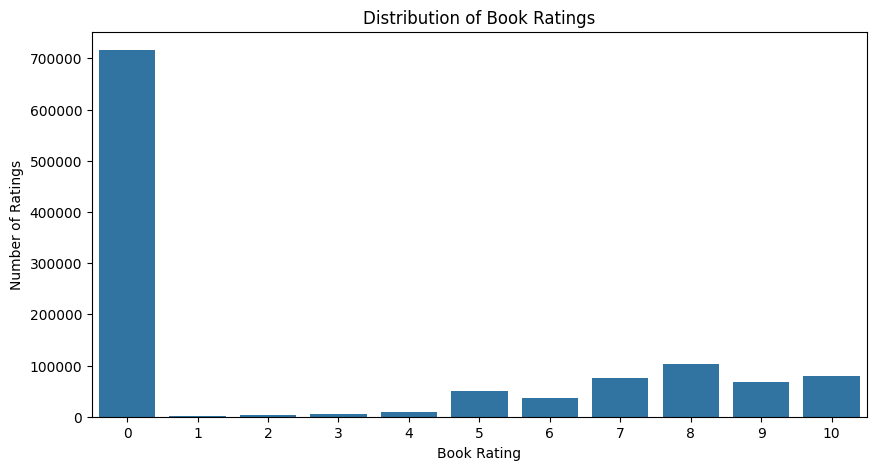

In [19]:

# Count ratings
rating_distribution = (
    bronze_ratings['Book-Rating']
    .value_counts()
    .sort_index()
)

print("Rating Distribution:")
print(rating_distribution)

# Count zero ratings
zero_count = (
    bronze_ratings['Book-Rating'].astype(str) == '0'
).sum()

print("\nNumber of Zero Ratings:", zero_count)

# Plot
plt.figure(figsize=(10, 5))

sns.countplot(
    data=bronze_ratings,
    x='Book-Rating',
    order=sorted(bronze_ratings['Book-Rating'].unique())
)

plt.title("Distribution of Book Ratings")
plt.xlabel("Book Rating")
plt.ylabel("Number of Ratings")
plt.show()


Age Statistics:
count    168096.000000
mean         34.751434
std          14.428097
min           0.000000
25%          24.000000
50%          32.000000
75%          44.000000
max         244.000000
Name: Age, dtype: float64

Missing Ages: 110762
Ages Below 5: 882
Ages Above 100: 366


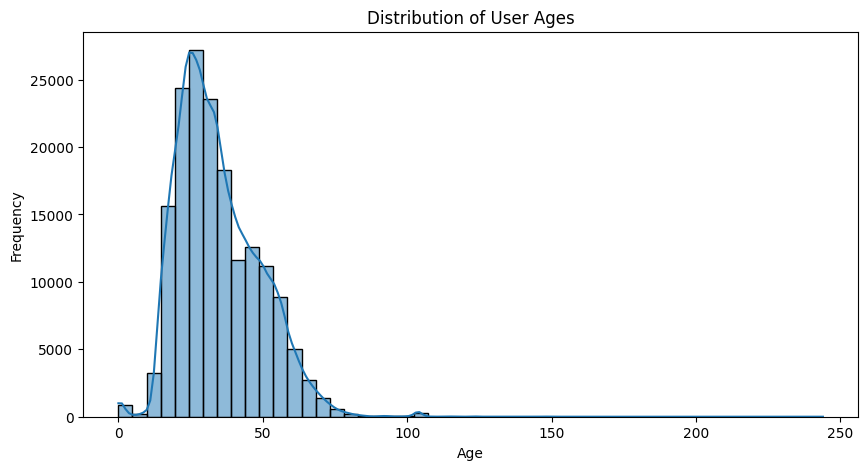

In [20]:

ages = pd.to_numeric(
    bronze_users['Age'],
    errors='coerce'
)

print("Age Statistics:")
print(ages.describe())

print("\nMissing Ages:", ages.isnull().sum())

print("Ages Below 5:", (ages < 5).sum())

print("Ages Above 100:", (ages > 100).sum())

plt.figure(figsize=(10, 5))

sns.histplot(
    ages.dropna(),
    bins=50,
    kde=True
)

plt.title("Distribution of User Ages")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()


Publication Year Statistics:
count       271357.0
mean     1959.760817
std       257.994226
min              0.0
25%           1989.0
50%           1995.0
75%           2000.0
max           2050.0
Name: Year-Of-Publication, dtype: Float64

Missing/Invalid Years: 3
Year 0: 4618
Future Years: 11


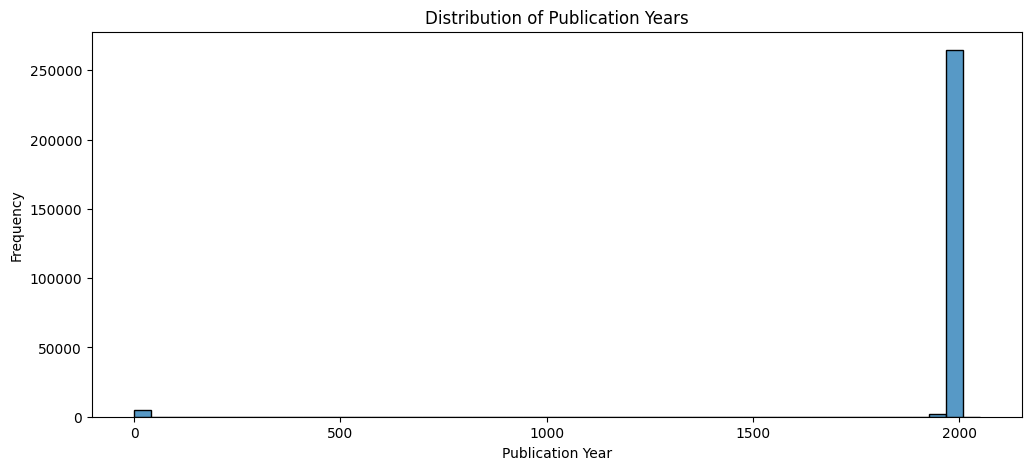

In [21]:

publication_years = pd.to_numeric(
    bronze_books['Year-Of-Publication'],
    errors='coerce'
)

current_year = datetime.now().year

print("Publication Year Statistics:")
print(publication_years.describe())

print("\nMissing/Invalid Years:",
      publication_years.isnull().sum())

print("Year 0:",
      (publication_years == 0).sum())

print("Future Years:",
      (publication_years > current_year).sum())

plt.figure(figsize=(12, 5))

sns.histplot(
    publication_years.dropna(),
    bins=50
)

plt.title("Distribution of Publication Years")
plt.xlabel("Publication Year")
plt.ylabel("Frequency")
plt.show()


Ratings Per User:
count    105283.000000
mean         10.920851
std          90.562825
min           1.000000
25%           1.000000
50%           1.000000
75%           4.000000
max       13602.000000
dtype: float64

Ratings Per Book:
count    340556.000000
mean          3.376185
std          12.436252
min           1.000000
25%           1.000000
50%           1.000000
75%           2.000000
max        2502.000000
dtype: float64

Users with only 1 rating: 59166
Books with only 1 rating: 197045


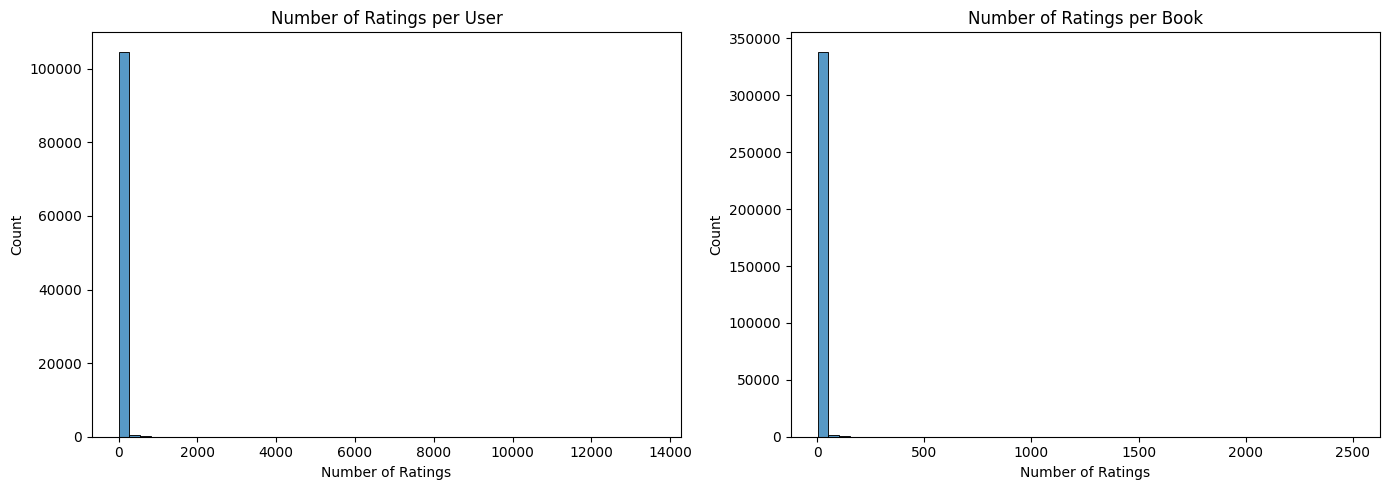

In [22]:

# Number of ratings given by each user
ratings_per_user = (
    bronze_ratings.groupby('User-ID')
    .size()
)

# Number of ratings received by each book
ratings_per_book = (
    bronze_ratings.groupby('ISBN')
    .size()
)

print("Ratings Per User:")
print(ratings_per_user.describe())

print("\nRatings Per Book:")
print(ratings_per_book.describe())

print("\nUsers with only 1 rating:",
      (ratings_per_user == 1).sum())

print("Books with only 1 rating:",
      (ratings_per_book == 1).sum())


# Visualize distributions
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    ratings_per_user,
    bins=50,
    ax=axes[0]
)

axes[0].set_title("Number of Ratings per User")
axes[0].set_xlabel("Number of Ratings")

sns.histplot(
    ratings_per_book,
    bins=50,
    ax=axes[1]
)

axes[1].set_title("Number of Ratings per Book")
axes[1].set_xlabel("Number of Ratings")

plt.tight_layout()
plt.show()


In [23]:

# Total unique users in Bronze
total_users = bronze_users['User-ID'].nunique()

# Total unique books in Bronze
total_books = bronze_books['ISBN'].nunique()

# Count unique user-book combinations
actual_rated_pairs = bronze_ratings[
    ['User-ID', 'ISBN']
].drop_duplicates().shape[0]

# Total possible combinations
possible_pairs = total_users * total_books

# Calculate sparsity
sparsity = (
    1 - actual_rated_pairs / possible_pairs
) * 100

print("Total Users:", total_users)
print("Total Books:", total_books)

print("Actual Rated Pairs:", actual_rated_pairs)

print("Possible User-Book Pairs:", possible_pairs)

print(f"\nMatrix Sparsity: {sparsity:.4f}%")

print(
    f"Matrix Density: {100-sparsity:.4f}%"
)


Total Users: 278858
Total Books: 271360
Actual Rated Pairs: 1149780
Possible User-Book Pairs: 75670906880

Matrix Sparsity: 99.9985%
Matrix Density: 0.0015%



## Bronze Layer – EDA Observations

1. Dataset Structure:
   Users: [278858, 4]
   Books: [271360, 9]
   Ratings: [1149780, 4]
   Action: Remove duplicates and validate data types in Silver.

2. Missing Values:
   Users contain 110,762 missing values.
   Books contain 7 missing values.
   Ratings contain 0 missing values.
   Action: Handle missing values according to column requirements.

3. Rating Distribution:
   Zero ratings: 716,109.
   Action: Remove zero ratings and retain ratings from 1 to 10.

4. User Age Distribution:
   Invalid ages below 5: 882.
   Invalid ages above 100: 366.
   Action: Convert invalid ages to null and fill missing ages with median.

5. Publication Year Distribution:
   Year 0 values: 4,618.
   Future publication years: 11.
   Action: Convert invalid publication years to null.


6. Ratings per User and Book: Minimum ratings per user: 1. Median ratings per user: 1. Minimum ratings per book: 1. Median ratings per book: 1. Mean ratings per user: 10.92. Mean ratings per book: 3.38. Users with only 1 rating: 59,166. Books with only 1 rating: 197,045. Action: Retain users and books having at least 10 ratings to reduce sparsity and improve recommendation reliability.


7. Matrix Sparsity:
   The rating matrix has 99.9985% sparsity.
   Action: Use a sparse matrix in the Gold layer to save memory.



## Minimum Rating Threshold

A minimum threshold of 10 ratings was selected for both users and books.

EDA showed that the median number of ratings per user and book was only 1, with 59,166 users and 197,045 books having only one rating.

A threshold of 10 helps remove users and books with insufficient interaction history, improving the reliability of item-based collaborative filtering recommendations.

The filtering will be applied iteratively until all retained users and books have at least 10 explicit ratings.


In [24]:

import pandas as pd
import numpy as np
import os

# Read Bronze datasets
users = pd.read_parquet("bronze/users.parquet")
books = pd.read_parquet("bronze/books.parquet")
ratings = pd.read_parquet("bronze/ratings.parquet")

print("Bronze datasets loaded successfully!")

print("Users:", users.shape)
print("Books:", books.shape)
print("Ratings:", ratings.shape)


Bronze datasets loaded successfully!
Users: (278858, 4)
Books: (271360, 9)
Ratings: (1149780, 4)


In [25]:

# Remove duplicate rows
users = users.drop_duplicates()
books = books.drop_duplicates()
ratings = ratings.drop_duplicates()

# Ensure unique user and book identifiers
users = users.drop_duplicates(subset=["User-ID"])
books = books.drop_duplicates(subset=["ISBN"])

print("Duplicates removed successfully!")

print("Users:", users.shape)
print("Books:", books.shape)
print("Ratings:", ratings.shape)


Duplicates removed successfully!
Users: (278858, 4)
Books: (271360, 9)
Ratings: (1149780, 4)


In [26]:

# Convert ratings to numeric
ratings["Book-Rating"] = pd.to_numeric(
    ratings["Book-Rating"], errors="coerce"
)

# Keep only explicit ratings between 1 and 10
ratings = ratings[
    ratings["Book-Rating"].between(1, 10)
].copy()

ratings["Book-Rating"] = ratings["Book-Rating"].astype("int8")

print("Ratings cleaned successfully!")
print("Remaining ratings:", len(ratings))
print("Rating range:",
      ratings["Book-Rating"].min(),
      "to",
      ratings["Book-Rating"].max())

print("Zero ratings:",
      (ratings["Book-Rating"] == 0).sum())


Ratings cleaned successfully!
Remaining ratings: 433671
Rating range: 1 to 10
Zero ratings: 0


In [27]:

# Convert Age to numeric
users["Age"] = pd.to_numeric(
    users["Age"], errors="coerce"
)

# Replace invalid ages with NaN
users.loc[
    (users["Age"] < 5) | (users["Age"] > 100),
    "Age"
] = np.nan

# Calculate median age
median_age = users["Age"].median()

# Fill missing ages
users["Age"] = users["Age"].fillna(median_age)

# Convert to integer
users["Age"] = users["Age"].round().astype("int64")

print("Age cleaning completed!")
print("Median Age:", median_age)
print("Remaining Missing Ages:", users["Age"].isnull().sum())

print(users["Age"].describe())


Age cleaning completed!
Median Age: 32.0
Remaining Missing Ages: 0
count    278858.000000
mean         33.643385
std          10.630979
min           5.000000
25%          29.000000
50%          32.000000
75%          35.000000
max         100.000000
Name: Age, dtype: float64


In [28]:

# Clean location text
users["Location"] = (
    users["Location"]
    .fillna("")
    .astype(str)
    .str.strip()
    .str.lower()
)

# Split into three components
location_parts = users["Location"].str.split(
    ",", n=2, expand=True
)

# Create separate columns
users["City"] = location_parts[0].str.strip()

users["State"] = (
    location_parts[1].str.strip()
    if 1 in location_parts.columns
    else ""
)

users["Country"] = (
    location_parts[2].str.strip()
    if 2 in location_parts.columns
    else ""
)

# Standardize case
for col in ["City", "State", "Country"]:
    users[col] = users[col].fillna("").str.title()

# Remove original Location column
users = users.drop(columns=["Location"])

print("Location splitting completed!")
display(users[["City", "State", "Country"]].head())


Location splitting completed!


,City,State,Country
0,Nyc,New York,Usa
1,Stockton,California,Usa
2,Moscow,Yukon Territory,Russia
3,Porto,V.N.Gaia,Portugal
4,Farnborough,Hants,United Kingdom


In [29]:

# Convert publication year to numeric
books["Year-Of-Publication"] = pd.to_numeric(
    books["Year-Of-Publication"],
    errors="coerce"
)

# Convert invalid years to NaN
current_year = pd.Timestamp.now().year

books.loc[
    (books["Year-Of-Publication"] <= 0) |
    (books["Year-Of-Publication"] > current_year),
    "Year-Of-Publication"
] = np.nan

# Keep nullable integer format
books["Year-Of-Publication"] = (
    books["Year-Of-Publication"].astype("Int64")
)

print("Publication years cleaned!")
print("Invalid years remaining:",
      (
          (books["Year-Of-Publication"] <= 0) |
          (books["Year-Of-Publication"] > current_year)
      ).sum())

print("Missing publication years:",
      books["Year-Of-Publication"].isnull().sum())


Publication years cleaned!
Invalid years remaining: 0
Missing publication years: 4632


In [30]:

# Clean text columns in Users
for col in ["City", "State", "Country"]:
    users[col] = users[col].astype(str).str.strip()

# Clean text columns in Books
text_columns = [
    "Book-Title",
    "Book-Author",
    "Publisher"
]

for col in text_columns:
    books[col] = (
        books[col]
        .fillna("Unknown")
        .astype(str)
        .str.strip()
        .str.replace(r"\s+", " ", regex=True)
        .str.title()
    )

# Standardize ISBN
books["ISBN"] = books["ISBN"].astype(str).str.strip().str.upper()
ratings["ISBN"] = ratings["ISBN"].astype(str).str.strip().str.upper()

# Remove image URL columns
image_columns = [
    col for col in books.columns
    if "Image-URL" in col
]

books = books.drop(columns=image_columns)

print("Text cleaning completed!")
print("Removed image columns:", image_columns)

display(books.head())


Text cleaning completed!
Removed image columns: ['Image-URL-S', 'Image-URL-M', 'Image-URL-L']


,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher,ingestion_timestamp
0,0195153448,Classical Mythology,Mark P. O. Morford,2002,Oxford University Press,2026-11-26 16:28:09.482201+00:00
1,0002005018,Clara Callan,Richard Bruce Wright,2001,Harperflamingo Canada,2026-11-26 16:28:09.482201+00:00
2,0060973129,Decision In Normandy,Carlo D'Este,1991,Harperperennial,2026-11-26 16:28:09.482201+00:00
3,0374157065,Flu: The Story Of The Great Influenza Pandemic...,Gina Bari Kolata,1999,Farrar Straus Giroux,2026-11-26 16:28:09.482201+00:00
4,0393045218,The Mummies Of Urumchi,E. J. W. Barber,1999,W. W. Norton &Amp; Company,2026-11-26 16:28:09.482201+00:00


In [31]:

# Keep ratings belonging to existing users
ratings = ratings[
    ratings["User-ID"].isin(users["User-ID"])
]

# Keep ratings belonging to existing books
ratings = ratings[
    ratings["ISBN"].isin(books["ISBN"])
]

print("Referential integrity check completed!")

print("Ratings:", ratings.shape)
print("Valid Users:", ratings["User-ID"].nunique())
print("Valid Books:", ratings["ISBN"].nunique())


Referential integrity check completed!
Ratings: (383843, 4)
Valid Users: 68091
Valid Books: 149717


In [32]:

MIN_RATINGS = 10

previous_shape = None

while previous_shape != ratings.shape:
    previous_shape = ratings.shape

    # Count ratings per user
    user_counts = ratings.groupby("User-ID").size()

    # Keep users with at least 10 ratings
    valid_users = user_counts[
        user_counts >= MIN_RATINGS
    ].index

    ratings = ratings[
        ratings["User-ID"].isin(valid_users)
    ]

    # Count ratings per book
    book_counts = ratings.groupby("ISBN").size()

    # Keep books with at least 10 ratings
    valid_books = book_counts[
        book_counts >= MIN_RATINGS
    ].index

    ratings = ratings[
        ratings["ISBN"].isin(valid_books)
    ]

# Retain only corresponding users and books
users = users[
    users["User-ID"].isin(ratings["User-ID"].unique())
].copy()

books = books[
    books["ISBN"].isin(ratings["ISBN"].unique())
].copy()

print("Minimum rating threshold applied!")

print("Minimum ratings per user:",
      ratings.groupby("User-ID").size().min())

print("Minimum ratings per book:",
      ratings.groupby("ISBN").size().min())

print("\nFinal Dataset Shapes:")
print("Users:", users.shape)
print("Books:", books.shape)
print("Ratings:", ratings.shape)


Minimum rating threshold applied!
Minimum ratings per user: 10
Minimum ratings per book: 10

Final Dataset Shapes:
Users: (1820, 6)
Books: (2087, 6)
Ratings: (41469, 4)


In [33]:

print("=" * 55)
print("SILVER LAYER VALIDATION")
print("=" * 55)

print("\n1. Dataset Shapes")
print("Users:", users.shape)
print("Books:", books.shape)
print("Ratings:", ratings.shape)

print("\n2. Missing Values")
print("Users:\n", users.isnull().sum())
print("\nBooks:\n", books.isnull().sum())
print("\nRatings:\n", ratings.isnull().sum())

print("\n3. Rating Range")
print("Minimum:", ratings["Book-Rating"].min())
print("Maximum:", ratings["Book-Rating"].max())

print("\n4. Zero Ratings")
print((ratings["Book-Rating"] == 0).sum())

print("\n5. Duplicate Records")
print("Users:", users.duplicated().sum())
print("Books:", books.duplicated().sum())
print("Ratings:", ratings.duplicated().sum())

print("\n6. Minimum Ratings")
print("Per User:",
      ratings.groupby("User-ID").size().min())
print("Per Book:",
      ratings.groupby("ISBN").size().min())

print("\n7. Referential Integrity")
print("Invalid users:",
      (~ratings["User-ID"].isin(users["User-ID"])).sum())

print("Invalid books:",
      (~ratings["ISBN"].isin(books["ISBN"])).sum())

print("\n8. Image URL Columns")
print([c for c in books.columns if "Image-URL" in c])

print("\n" + "=" * 55)


SILVER LAYER VALIDATION

1. Dataset Shapes
Users: (1820, 6)
Books: (2087, 6)
Ratings: (41469, 4)

2. Missing Values
Users:
 User-ID                0
Age                    0
ingestion_timestamp    0
City                   0
State                  0
Country                0
dtype: int64

Books:
 ISBN                   0
Book-Title             0
Book-Author            0
Year-Of-Publication    4
Publisher              0
ingestion_timestamp    0
dtype: int64

Ratings:
 User-ID                0
ISBN                   0
Book-Rating            0
ingestion_timestamp    0
dtype: int64

3. Rating Range
Minimum: 1
Maximum: 10

4. Zero Ratings
0

5. Duplicate Records
Users: 0
Books: 56
Ratings: 0

6. Minimum Ratings
Per User: 10
Per Book: 10

7. Referential Integrity
Invalid users: 0
Invalid books: 0

8. Image URL Columns
[]



In [34]:

# Remove duplicate books using ISBN as the unique identifier
books = books.drop_duplicates(
    subset=["ISBN"],
    keep="first"
).copy()

# Remove any ratings referring to books that no longer exist
ratings = ratings[
    ratings["ISBN"].isin(books["ISBN"])
].copy()

# Keep only books that have ratings
books = books[
    books["ISBN"].isin(ratings["ISBN"])
].copy()

print("Duplicate books removed!")

print("Remaining duplicate ISBNs:",
      books["ISBN"].duplicated().sum())

print("Remaining duplicate book rows:",
      books.duplicated().sum())

print("Final Books:", books.shape)
print("Final Ratings:", ratings.shape)


Duplicate books removed!
Remaining duplicate ISBNs: 0
Remaining duplicate book rows: 0
Final Books: (2030, 6)
Final Ratings: (41469, 4)


In [35]:
print("Users:", users.duplicated().sum())
print("Books:", books.duplicated().sum())
print("Ratings:", ratings.duplicated().sum())

Users: 0
Books: 0
Ratings: 0


In [36]:

# Create Silver directory
os.makedirs("silver", exist_ok=True)

# Save cleaned datasets
users.to_parquet(
    "silver/users.parquet",
    index=False
)

books.to_parquet(
    "silver/books.parquet",
    index=False
)

ratings.to_parquet(
    "silver/ratings.parquet",
    index=False
)

print("Silver Layer created successfully!")

print("\nSaved Files:")
print("silver/users.parquet")
print("silver/books.parquet")
print("silver/ratings.parquet")


Silver Layer created successfully!

Saved Files:
silver/users.parquet
silver/books.parquet
silver/ratings.parquet


In [37]:

users.to_parquet("silver/users.parquet", index=False)
books.to_parquet("silver/books.parquet", index=False)
ratings.to_parquet("silver/ratings.parquet", index=False)

print("Updated Silver Layer saved successfully!")


Updated Silver Layer saved successfully!


In [38]:

silver_users = pd.read_parquet("silver/users.parquet")
silver_books = pd.read_parquet("silver/books.parquet")
silver_ratings = pd.read_parquet("silver/ratings.parquet")

print("Silver datasets reloaded successfully!")

display(silver_users.head())
display(silver_books.head())
display(silver_ratings.head())


Silver datasets reloaded successfully!


,User-ID,Age,ingestion_timestamp,City,State,Country
0,243,32,2026-11-26 16:28:09.482201+00:00,Arden Hills,Minnesota,Usa
1,254,24,2026-11-26 16:28:09.482201+00:00,Minneapolis,Minnesota,Usa
2,638,20,2026-11-26 16:28:09.482201+00:00,San Diego,California,Usa
3,805,34,2026-11-26 16:28:09.482201+00:00,Sonoma,California,Usa
4,882,23,2026-11-26 16:28:09.482201+00:00,Berkeley,California,Usa


,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher,ingestion_timestamp
0,0440234743,The Testament,John Grisham,1999,Dell,2026-11-26 16:28:09.482201+00:00
1,0452264464,Beloved (Plume Contemporary Fiction),Toni Morrison,1994,Plume,2026-11-26 16:28:09.482201+00:00
2,0971880107,Wild Animus,Rich Shapero,2004,Too Far,2026-11-26 16:28:09.482201+00:00
3,0345402871,Airframe,Michael Crichton,1997,Ballantine Books,2026-11-26 16:28:09.482201+00:00
4,0345417623,Timeline,Michael Crichton,2000,Ballantine Books,2026-11-26 16:28:09.482201+00:00


,User-ID,ISBN,Book-Rating,ingestion_timestamp
0,277427,002542730X,10,2026-11-26 16:28:09.482201+00:00
1,277427,0060542128,7,2026-11-26 16:28:09.482201+00:00
2,277427,0061009059,9,2026-11-26 16:28:09.482201+00:00
3,277427,0316776963,8,2026-11-26 16:28:09.482201+00:00
4,277427,0345413903,10,2026-11-26 16:28:09.482201+00:00



## Silver Layer – Results and Observations

The Bronze datasets were successfully cleaned and transformed into the Silver layer.

The following transformations were performed:

1. Removed duplicate records from Users, Books and Ratings.
2. Removed zero ratings and retained explicit ratings between 1 and 10.
3. Replaced invalid ages (below 5 and above 100) with null values and filled missing ages using the median.
4. Split the Location column into City, State and Country.
5. Converted invalid publication years (0 and future years) into null values.
6. Standardized text columns and removed unnecessary image URL columns.
7. Maintained referential integrity by removing ratings associated with nonexistent users or books.
8. Applied a minimum threshold of 10 ratings per user and per book using iterative filtering.
9. Saved the cleaned datasets in Parquet format in the Silver directory.

The resulting Silver datasets are clean, consistent and suitable for building the recommendation model.



# Step 4: Gold Layer – Model-Ready Data

The Gold layer contains aggregated and structured data prepared for machine learning.

The following datasets will be created:

1. User-Book Rating Matrix: A sparse matrix containing books as rows, users as columns and ratings as values.
2. Book Lookup Table: Contains ISBN, book title and author.
3. User Aggregates: Contains average rating and total number of ratings per user.
4. Book Aggregates: Contains average rating and total number of ratings per book.

These datasets will be used to build an Item-Based Collaborative Filtering Recommender System.


In [39]:

import pandas as pd
import numpy as np
import os

from scipy.sparse import csr_matrix, save_npz, load_npz

# Create Gold directory
os.makedirs("gold", exist_ok=True)

# Load Silver datasets
silver_users = pd.read_parquet("silver/users.parquet")
silver_books = pd.read_parquet("silver/books.parquet")
silver_ratings = pd.read_parquet("silver/ratings.parquet")

print("Silver datasets loaded successfully!")

print("Users:", silver_users.shape)
print("Books:", silver_books.shape)
print("Ratings:", silver_ratings.shape)


Silver datasets loaded successfully!
Users: (1820, 6)
Books: (2030, 6)
Ratings: (41469, 4)


In [40]:

# Select required columns
model_ratings = silver_ratings[
    ["User-ID", "ISBN", "Book-Rating"]
].copy()

# Ensure correct data types
model_ratings["User-ID"] = model_ratings["User-ID"].astype("int64")
model_ratings["ISBN"] = model_ratings["ISBN"].astype(str)
model_ratings["Book-Rating"] = pd.to_numeric(
    model_ratings["Book-Rating"]
)

# Aggregate duplicate user-book combinations, if any
model_ratings = (
    model_ratings
    .groupby(["ISBN", "User-ID"], as_index=False)
    ["Book-Rating"]
    .mean()
)

print("Ratings prepared for the model!")

print("Total interactions:", len(model_ratings))
print("Unique users:", model_ratings["User-ID"].nunique())
print("Unique books:", model_ratings["ISBN"].nunique())

print("Duplicate user-book pairs:",
      model_ratings.duplicated(["ISBN", "User-ID"]).sum())


Ratings prepared for the model!
Total interactions: 41469
Unique users: 1820
Unique books: 2030
Duplicate user-book pairs: 0


In [41]:

# Create sorted unique identifiers
book_ids = sorted(model_ratings["ISBN"].unique())
user_ids = sorted(model_ratings["User-ID"].unique())

# Create mappings
book_to_index = {
    book_id: index
    for index, book_id in enumerate(book_ids)
}

user_to_index = {
    user_id: index
    for index, user_id in enumerate(user_ids)
}

# Convert identifiers into matrix positions
row_indices = model_ratings["ISBN"].map(book_to_index).values
col_indices = model_ratings["User-ID"].map(user_to_index).values

rating_values = model_ratings["Book-Rating"].values

print("Index mappings created!")

print("Number of book rows:", len(book_ids))
print("Number of user columns:", len(user_ids))

print("\nSample Book Mapping:")
print(list(book_to_index.items())[:5])

print("\nSample User Mapping:")
print(list(user_to_index.items())[:5])


Index mappings created!
Number of book rows: 2030
Number of user columns: 1820

Sample Book Mapping:
[('0020199600', 0), ('0020442203', 1), ('002542730X', 2), ('0028604199', 3), ('0060002050', 4)]

Sample User Mapping:
[(np.int64(243), 0), (np.int64(254), 1), (np.int64(638), 2), (np.int64(805), 3), (np.int64(882), 4)]


In [42]:

# Create sparse matrix
rating_matrix = csr_matrix(
    (
        rating_values,
        (row_indices, col_indices)
    ),
    shape=(len(book_ids), len(user_ids)),
    dtype=np.float32
)

print("Sparse User-Book Matrix Created!")

print("Matrix Shape:", rating_matrix.shape)
print("Number of Ratings:", rating_matrix.nnz)
print("Matrix Type:", type(rating_matrix))
print("Data Type:", rating_matrix.dtype)

# Calculate sparsity
total_elements = (
    rating_matrix.shape[0] * rating_matrix.shape[1]
)

sparsity = (
    1 - rating_matrix.nnz / total_elements
) * 100

print(f"Matrix Sparsity: {sparsity:.4f}%")
print(f"Matrix Density: {100 - sparsity:.4f}%")


Sparse User-Book Matrix Created!
Matrix Shape: (2030, 1820)
Number of Ratings: 41469
Matrix Type: <class 'scipy.sparse._csr.csr_matrix'>
Data Type: float32
Matrix Sparsity: 98.8776%
Matrix Density: 1.1224%


In [43]:

# Create sparse matrix
rating_matrix = csr_matrix(
    (
        rating_values,
        (row_indices, col_indices)
    ),
    shape=(len(book_ids), len(user_ids)),
    dtype=np.float32
)

print("Sparse User-Book Matrix Created!")

print("Matrix Shape:", rating_matrix.shape)
print("Number of Ratings:", rating_matrix.nnz)
print("Matrix Type:", type(rating_matrix))
print("Data Type:", rating_matrix.dtype)

# Calculate sparsity
total_elements = (
    rating_matrix.shape[0] * rating_matrix.shape[1]
)

sparsity = (
    1 - rating_matrix.nnz / total_elements
) * 100

print(f"Matrix Sparsity: {sparsity:.4f}%")
print(f"Matrix Density: {100 - sparsity:.4f}%")


Sparse User-Book Matrix Created!
Matrix Shape: (2030, 1820)
Number of Ratings: 41469
Matrix Type: <class 'scipy.sparse._csr.csr_matrix'>
Data Type: float32
Matrix Sparsity: 98.8776%
Matrix Density: 1.1224%


In [44]:

# Save sparse matrix
save_npz(
    "gold/user_book_matrix.npz",
    rating_matrix
)

# Save book index mapping
book_mapping = pd.DataFrame({
    "ISBN": book_ids,
    "book_index": range(len(book_ids))
})

book_mapping.to_csv(
    "gold/book_index.csv",
    index=False
)

# Save user index mapping
user_mapping = pd.DataFrame({
    "User-ID": user_ids,
    "user_index": range(len(user_ids))
})

user_mapping.to_csv(
    "gold/user_index.csv",
    index=False
)

print("Sparse matrix and index mappings saved successfully!")


Sparse matrix and index mappings saved successfully!


In [45]:

# Create book lookup table
book_lookup = silver_books[
    ["ISBN", "Book-Title", "Book-Author"]
].copy()

# Remove duplicate ISBNs if any
book_lookup = book_lookup.drop_duplicates(
    subset=["ISBN"],
    keep="first"
)

# Keep only books present in the rating matrix
book_lookup = book_lookup[
    book_lookup["ISBN"].isin(book_ids)
].copy()

# Save lookup table
book_lookup.to_csv(
    "gold/book_lookup.csv",
    index=False
)

print("Book Lookup Table Created!")

print("Total Books:", len(book_lookup))

display(book_lookup.head(10))


Book Lookup Table Created!
Total Books: 2030


,ISBN,Book-Title,Book-Author
0,0440234743,The Testament,John Grisham
1,0452264464,Beloved (Plume Contemporary Fiction),Toni Morrison
2,0971880107,Wild Animus,Rich Shapero
3,0345402871,Airframe,Michael Crichton
4,0345417623,Timeline,Michael Crichton
5,0446310786,To Kill A Mockingbird,Harper Lee
6,0449005615,Seabiscuit: An American Legend,Laura Hillenbrand
7,0671888587,I'Ll Be Seeing You,Mary Higgins Clark
8,0553582747,From The Corner Of His Eye,Dean Koontz
9,0425182908,Isle Of Dogs,Patricia Cornwell


In [46]:

user_aggregates = (
    model_ratings
    .groupby("User-ID")
    .agg(
        average_rating=("Book-Rating", "mean"),
        number_of_ratings=("Book-Rating", "count")
    )
    .reset_index()
)

# Save user aggregates
user_aggregates.to_csv(
    "gold/user_aggregates.csv",
    index=False
)

print("User Aggregates Created!")

display(
    user_aggregates.sort_values(
        "number_of_ratings",
        ascending=False
    ).head(10)
)


User Aggregates Created!


,User-ID,average_rating,number_of_ratings
59,11676,7.705451,954
86,16795,7.818182,242
607,95359,8.005128,195
668,104636,8.732620,187
737,114368,6.784091,176
1012,153662,9.255814,172
369,60244,8.157143,140
1039,158295,6.644928,138
624,98391,9.007299,137
212,35859,7.688000,125


In [47]:

book_aggregates = (
    model_ratings
    .groupby("ISBN")
    .agg(
        average_rating=("Book-Rating", "mean"),
        number_of_ratings=("Book-Rating", "count")
    )
    .reset_index()
)

# Save book aggregates
book_aggregates.to_csv(
    "gold/book_aggregates.csv",
    index=False
)

print("Book Aggregates Created!")

# Display books with highest average ratings
display(
    book_aggregates.sort_values(
        ["average_rating", "number_of_ratings"],
        ascending=[False, False]
    ).head(10)
)


Book Aggregates Created!


,ISBN,average_rating,number_of_ratings
1529,0618002235,9.933333,15
1911,0836213319,9.916667,12
872,0439425220,9.866667,15
700,0394800389,9.818182,11
1347,0517693119,9.800000,10
21,0060256656,9.769231,13
1915,0836218221,9.692308,13
1927,0836220889,9.647059,17
2028,193156146X,9.642857,14
105,006440188X,9.625000,16


In [48]:

print("=" * 55)
print("GOLD LAYER VALIDATION")
print("=" * 55)

# Reload sparse matrix
loaded_matrix = load_npz(
    "gold/user_book_matrix.npz"
)

# Reload saved files
loaded_book_lookup = pd.read_csv(
    "gold/book_lookup.csv",
    dtype={"ISBN": str}
)

loaded_user_aggregates = pd.read_csv(
    "gold/user_aggregates.csv"
)

loaded_book_aggregates = pd.read_csv(
    "gold/book_aggregates.csv"
)

print("\n1. Sparse Rating Matrix")
print("Shape:", loaded_matrix.shape)
print("Non-zero ratings:", loaded_matrix.nnz)
print("Matrix type:", type(loaded_matrix))

print("\n2. Book Lookup Table")
print("Shape:", loaded_book_lookup.shape)

print("\n3. User Aggregates")
print("Shape:", loaded_user_aggregates.shape)

print("\n4. Book Aggregates")
print("Shape:", loaded_book_aggregates.shape)

print("\n5. Minimum Ratings")
print("Per user:",
      loaded_user_aggregates["number_of_ratings"].min())

print("Per book:",
      loaded_book_aggregates["number_of_ratings"].min())

print("\n6. Saved Gold Files")

for file in sorted(os.listdir("gold")):
    print(file)

print("\n" + "=" * 55)
print("GOLD LAYER CREATED SUCCESSFULLY!")
print("=" * 55)


GOLD LAYER VALIDATION

1. Sparse Rating Matrix
Shape: (2030, 1820)
Non-zero ratings: 41469
Matrix type: <class 'scipy.sparse._csr.csr_matrix'>

2. Book Lookup Table
Shape: (2030, 3)

3. User Aggregates
Shape: (1820, 3)

4. Book Aggregates
Shape: (2030, 3)

5. Minimum Ratings
Per user: 10
Per book: 10

6. Saved Gold Files
book_aggregates.csv
book_index.csv
book_lookup.csv
user_aggregates.csv
user_book_matrix.npz
user_index.csv

GOLD LAYER CREATED SUCCESSFULLY!



# Gold Layer – Results and Observations

The Gold layer was successfully created from the cleaned Silver datasets.

The following model-ready datasets were generated:

1. User-Book Rating Matrix: Created a sparse matrix with books as rows and users as columns using SciPy CSR format.
2. Book Lookup Table: Created a table containing ISBN, book title and author for displaying readable recommendations.
3. User-Level Aggregates: Calculated the average rating and total number of ratings for each user.
4. Book-Level Aggregates: Calculated the average rating and total number of ratings for each book.

The sparse matrix was saved in NPZ format to reduce memory consumption. Lookup tables, index mappings and aggregate datasets were saved as CSV files.

These Gold datasets will serve as input for the Item-Based Collaborative Filtering Recommender System.


In [49]:

import numpy as np
import pandas as pd
import os

from scipy.sparse import load_npz
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics.pairwise import cosine_similarity

# Load Gold Layer datasets
rating_matrix = load_npz("gold/user_book_matrix.npz")

book_lookup = pd.read_csv(
    "gold/book_lookup.csv",
    dtype={"ISBN": str}
)

book_index = pd.read_csv(
    "gold/book_index.csv",
    dtype={"ISBN": str}
)

user_index = pd.read_csv("gold/user_index.csv")

user_aggregates = pd.read_csv(
    "gold/user_aggregates.csv"
)

book_aggregates = pd.read_csv(
    "gold/book_aggregates.csv"
)

# Display dataset information
print("GOLD DATASETS LOADED SUCCESSFULLY!")

print("\nRating Matrix:", rating_matrix.shape)
print("Book Lookup:", book_lookup.shape)
print("Book Index:", book_index.shape)
print("User Index:", user_index.shape)
print("User Aggregates:", user_aggregates.shape)
print("Book Aggregates:", book_aggregates.shape)


GOLD DATASETS LOADED SUCCESSFULLY!

Rating Matrix: (2030, 1820)
Book Lookup: (2030, 3)
Book Index: (2030, 2)
User Index: (1820, 2)
User Aggregates: (1820, 3)
Book Aggregates: (2030, 3)


In [50]:

# Initialize Item-Based Collaborative Filtering Model

knn_model = NearestNeighbors(
    metric="cosine",
    algorithm="brute",
    n_neighbors=11,
    n_jobs=-1
)

# Fit model on book-user rating matrix
knn_model.fit(rating_matrix)

print("Item-Based Collaborative Filtering Model Created!")
print("Algorithm: K-Nearest Neighbors")
print("Similarity Metric: Cosine Similarity")
print("Number of Neighbors: 11")
print("Number of Books:", rating_matrix.shape[0])
print("Number of Users:", rating_matrix.shape[1])


Item-Based Collaborative Filtering Model Created!
Algorithm: K-Nearest Neighbors
Similarity Metric: Cosine Similarity
Number of Neighbors: 11
Number of Books: 2030
Number of Users: 1820


In [51]:

def get_similar_books(book_title, n_recommendations=10):

    matched = book_lookup[
        book_lookup["Book-Title"].str.strip().str.lower()
        == book_title.strip().lower()
    ]

    if matched.empty:
        print("Book not found!")
        return pd.DataFrame()

    isbn = matched.iloc[0]["ISBN"]

    book_to_idx = dict(zip(
        book_index["ISBN"],
        book_index["book_index"]
    ))

    idx_to_book = book_lookup.drop_duplicates(
        "ISBN"
    ).set_index("ISBN")

    idx_to_isbn = dict(zip(
        book_index["book_index"],
        book_index["ISBN"]
    ))

    book_idx = book_to_idx[isbn]

    distances, indices = knn_model.kneighbors(
        rating_matrix[book_idx],
        n_neighbors=n_recommendations + 1
    )

    results = []

    for distance, idx in zip(
        distances.flatten(),
        indices.flatten()
    ):

        if idx == book_idx:
            continue

        recommended_isbn = idx_to_isbn[idx]
        book = idx_to_book.loc[recommended_isbn]

        results.append({
            "Book-Title": book["Book-Title"],
            "Book-Author": book["Book-Author"],
            "Similarity Score": round(1 - distance, 4)
        })

    return pd.DataFrame(results)



In [52]:

# Select a sample book
sample_book = book_lookup.iloc[0]["Book-Title"]

print("Input Book:", sample_book)
print("\nRecommended Books:\n")

recommendations = get_similar_books(
    sample_book,
    n_recommendations=10
)

display(recommendations)


Input Book: The Testament

Recommended Books:



,Book-Title,Book-Author,Similarity Score
0,Monster : A Novel (Alex Delaware Novels (Paper...,Jonathan Kellerman,0.2528
1,The Runaway Jury,John Grisham,0.2378
2,The Bone Collector (Lincoln Rhyme Novels (Pape...,Jeff Deaver,0.2376
3,Call Of The Wild,Jack London,0.2359
4,The Simple Truth,David Baldacci,0.2356
5,The Street Lawyer,John Grisham,0.2198
6,Atlantis Found,Clive Cussler,0.1994
7,Outbreak,Robin Cook,0.1987
8,From Potter'S Field,Patricia Daniels Cornwell,0.1962
9,Writ Of Execution,Perri O'Shaughnessy,0.1901


In [53]:

def recommend_for_user(user_id, n=10):

    # Check whether user exists
    user_col = user_index.loc[
        user_index["User-ID"] == user_id,
        "user_index"
    ]

    if user_col.empty:
        print("User not found!")
        return pd.DataFrame()

    user_col = user_col.iloc[0]

    # Get user's rated books
    user_ratings = model_ratings[
        model_ratings["User-ID"] == user_id
    ]

    # Select highly rated books
    liked_books = user_ratings[
        user_ratings["Book-Rating"] >= 7
    ]

    if liked_books.empty:
        print("User has no highly rated books!")
        return pd.DataFrame()

    # Books already rated by user
    rated_isbns = set(user_ratings["ISBN"])

    recommendations = {}

    # Generate recommendations from liked books
    for isbn in liked_books["ISBN"]:

        book_idx = book_index.loc[
            book_index["ISBN"] == isbn,
            "book_index"
        ].iloc[0]

        distances, indices = knn_model.kneighbors(
            rating_matrix[book_idx],
            n_neighbors=11
        )

        for distance, idx in zip(
            distances.flatten(),
            indices.flatten()
        ):

            recommended_isbn = book_index.iloc[idx]["ISBN"]

            # Exclude already rated books
            if recommended_isbn in rated_isbns:
                continue

            similarity = 1 - distance

            recommendations[recommended_isbn] = (
                recommendations.get(recommended_isbn, 0)
                + similarity
            )

    if not recommendations:
        print("No recommendations found!")
        return pd.DataFrame()

    # Rank recommendations
    ranked = sorted(
        recommendations.items(),
        key=lambda x: x[1],
        reverse=True
    )[:n]

    results = []

    for isbn, score in ranked:

        book = book_lookup[
            book_lookup["ISBN"] == isbn
        ]

        if not book.empty:
            results.append({
                "ISBN": isbn,
                "Book-Title": book.iloc[0]["Book-Title"],
                "Book-Author": book.iloc[0]["Book-Author"],
                "Recommendation Score": round(score, 4)
            })

    return pd.DataFrame(results)


In [54]:

# Select a sample user with sufficient ratings
sample_user = (
    user_aggregates
    .sort_values("number_of_ratings", ascending=False)
    .iloc[0]["User-ID"]
)

print("Selected User ID:", sample_user)

print("\nUser's Reading History:")

display(
    model_ratings[
        model_ratings["User-ID"] == sample_user
    ].sort_values(
        "Book-Rating",
        ascending=False
    ).head(10)
)

print("\nPersonalized Recommendations:")

user_recommendations = recommend_for_user(
    sample_user,
    n=10
)

display(user_recommendations)


Selected User ID: 11676.0

User's Reading History:


,ISBN,User-ID,Book-Rating
235,0060175400,11676,10.0
41457,1931561648,11676,10.0
41444,193156146X,11676,10.0
279,006019491X,11676,10.0
294,0060199652,11676,10.0
41240,1573227889,11676,10.0
365,0060391626,11676,10.0
511,0060512822,11676,10.0
26772,0451526341,11676,10.0
25482,0451166604,11676,10.0



Personalized Recommendations:


,ISBN,Book-Title,Book-Author,Recommendation Score
0,0440167531,Palomino,Danielle Steel,4.2294
1,0373270976,"Night Shield (Intimate Moments, 1027)",Nora Roberts,3.3451
2,0670839531,Needful Things: The Last Castle Rock Story,Stephen King,2.5393
3,0399149848,Birthright,Nora Roberts,2.4965
4,0842332251,The Mark: The Beast Rules The World (Left Behi...,Tim Lahaye,2.4820
5,0312971346,High Five (A Stephanie Plum Novel),Janet Evanovich,2.3991
6,0439136350,Harry Potter And The Prisoner Of Azkaban (Book 3),J. K. Rowling,2.3695
7,0440168724,A Perfect Stranger,Danielle Steel,2.3465
8,0449221512,I Is For Innocent,Sue Grafton,2.3278
9,0842329285,The Indwelling: The Beast Takes Possession (Le...,Tim Lahaye,2.3270


In [55]:

from sklearn.model_selection import train_test_split
import pandas as pd
import numpy as np

# Use cleaned Gold-model ratings
ratings_df = model_ratings.copy()

# Split ratings user-wise
train_list = []
test_list = []

for user_id, group in ratings_df.groupby('User-ID'):

    if len(group) < 2:
        train_list.append(group)
        continue

    train, test = train_test_split(
        group,
        test_size=0.2,
        random_state=42
    )

    train_list.append(train)
    test_list.append(test)

# Combine datasets
train_ratings = pd.concat(train_list).reset_index(drop=True)
test_ratings = pd.concat(test_list).reset_index(drop=True)

# Display results
print("TRAIN-TEST SPLIT COMPLETED!")
print("-" * 45)

print("Original Ratings:", ratings_df.shape)
print("Training Ratings:", train_ratings.shape)
print("Testing Ratings:", test_ratings.shape)

print("\nUnique Users:")
print("Training:", train_ratings['User-ID'].nunique())
print("Testing:", test_ratings['User-ID'].nunique())

print("\nUnique Books:")
print("Training:", train_ratings['ISBN'].nunique())
print("Testing:", test_ratings['ISBN'].nunique())

print("\nMinimum Training Ratings per User:",
      train_ratings.groupby('User-ID').size().min())


TRAIN-TEST SPLIT COMPLETED!
---------------------------------------------
Original Ratings: (41469, 3)
Training Ratings: (32477, 3)
Testing Ratings: (8992, 3)

Unique Users:
Training: 1820
Testing: 1820

Unique Books:
Training: 2030
Testing: 1934

Minimum Training Ratings per User: 8


In [56]:

from scipy.sparse import csr_matrix
from sklearn.neighbors import NearestNeighbors

# Create item-user rating matrix using training data only
train_matrix = train_ratings.pivot_table(
    index='ISBN',
    columns='User-ID',
    values='Book-Rating',
    aggfunc='mean',
    fill_value=0
)

# Convert to sparse matrix
train_sparse_matrix = csr_matrix(train_matrix.values)

# Train KNN model
knn_eval_model = NearestNeighbors(
    metric='cosine',
    algorithm='brute',
    n_neighbors=min(12, train_matrix.shape[0])
)

knn_eval_model.fit(train_sparse_matrix)

# Store book indexing
eval_book_ids = train_matrix.index.tolist()

print("TRAINING KNN MODEL CREATED!")
print("-" * 45)

print("Training Matrix Shape:", train_matrix.shape)
print("Sparse Matrix Shape:", train_sparse_matrix.shape)
print("Number of Books:", len(eval_book_ids))
print("Number of Users:", train_matrix.shape[1])
print("Similarity Metric: Cosine")
print("Number of Neighbors: 11")


TRAINING KNN MODEL CREATED!
---------------------------------------------
Training Matrix Shape: (2030, 1820)
Sparse Matrix Shape: (2030, 1820)
Number of Books: 2030
Number of Users: 1820
Similarity Metric: Cosine
Number of Neighbors: 11


In [57]:

# Generate Top-10 recommendations for each user

def get_recommendations(user_id, top_n=10):

    if user_id not in train_matrix.columns:
        return []

    # Books already rated by the user in training
    user_ratings = train_matrix[user_id]
    rated_books = set(user_ratings[user_ratings > 0].index)

    # Candidate books
    candidate_indices = [
        i for i, book in enumerate(eval_book_ids)
        if book not in rated_books
    ]

    if not candidate_indices:
        return []

    # User's rated books
    rated_indices = [
        i for i, book in enumerate(eval_book_ids)
        if book in rated_books
    ]

    scores = {}

    # Calculate weighted similarity scores
    for idx in rated_indices:

        distances, neighbors = knn_eval_model.kneighbors(
            train_sparse_matrix[idx],
            n_neighbors=min(12, len(eval_book_ids))
        )

        for distance, neighbor_idx in zip(distances[0], neighbors[0]):

            book = eval_book_ids[neighbor_idx]

            if book in rated_books:
                continue

            similarity = 1 - distance

            if similarity <= 0:
                continue

            rating = user_ratings.iloc[idx]

            scores[book] = scores.get(book, 0) + similarity * rating

    recommendations = sorted(
        scores.items(),
        key=lambda x: x[1],
        reverse=True
    )

    return [book for book, score in recommendations[:top_n]]


# Test on sample users
sample_users = train_ratings['User-ID'].drop_duplicates().head(5)

for user_id in sample_users:

    recs = get_recommendations(user_id)

    print(f"\nUser ID: {user_id}")
    print("Recommended Books:", recs)
    print("Number of Recommendations:", len(recs))



User ID: 243
Recommended Books: ['0425137562', '0446603929', '0452282829', '0345439104', '0515103969', '0743237188', '067976402X', '0060914653', '0425154092', '0425147622']
Number of Recommendations: 10

User ID: 254
Recommended Books: ['0590353403', '043935806X', '059035342X', '0439139600', '0060934719', '0060199652', '0618002235', '0679879269', '0451207246', '0060652934']
Number of Recommendations: 10

User ID: 638
Recommended Books: ['0446532452', '0345339738', '074320607X', '0553802488', '0316693251', '0385421982', '006019491X', '0316603287', '0345452577', '0345339703']
Number of Recommendations: 10

User ID: 805
Recommended Books: ['006019491X', '044022425X', '0060256737', '0440212561', '0671683993', '0440217563', '0385722206', '0440214114', '0679442405', '0440176484']
Number of Recommendations: 10

User ID: 882
Recommended Books: ['0553250531', '0316155306', '0553802488', '0553289411', '0060542128', '0316780812', '0515114693', '0373483503', '0373483694', '0345427637']
Number of 

In [58]:

# Evaluation metrics

K = 10
RELEVANCE_THRESHOLD = 7

# Actual relevant books from test data
actual_relevant = (
    test_ratings[test_ratings['Book-Rating'] >= RELEVANCE_THRESHOLD]
    .groupby('User-ID')['ISBN']
    .apply(set)
    .to_dict()
)

precision_scores = []
recall_scores = []
f1_scores = []

for user_id in train_matrix.columns:

    relevant_books = actual_relevant.get(user_id, set())

    if not relevant_books:
        continue

    recommended_books = get_recommendations(user_id, top_n=K)

    if not recommended_books:
        precision_scores.append(0)
        recall_scores.append(0)
        f1_scores.append(0)
        continue

    hits = len(set(recommended_books) & relevant_books)

    precision = hits / K
    recall = hits / len(relevant_books)

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall > 0 else 0
    )

    precision_scores.append(precision)
    recall_scores.append(recall)
    f1_scores.append(f1)

# Average metrics
print("MODEL EVALUATION RESULTS")
print("=" * 45)

print(f"Precision@{K}: {np.mean(precision_scores):.4f}")
print(f"Recall@{K}:    {np.mean(recall_scores):.4f}")
print(f"F1-score@{K}:  {np.mean(f1_scores):.4f}")

print("\nEvaluated Users:", len(precision_scores))


MODEL EVALUATION RESULTS
Precision@10: 0.0448
Recall@10:    0.1058
F1-score@10:  0.0580

Evaluated Users: 1792


In [59]:

# Correct evaluation by considering only books in training catalogue

K = 10
training_catalogue = set(eval_book_ids)

# Relevant test books that the model can actually recommend
test_relevant = test_ratings[
    test_ratings['Book-Rating'] >= RELEVANCE_THRESHOLD
]

actual_relevant_catalog = (
    test_relevant[
        test_relevant['ISBN'].isin(training_catalogue)
    ]
    .groupby('User-ID')['ISBN']
    .apply(set)
    .to_dict()
)

# Count relevant books unavailable in training catalogue
all_relevant = (
    test_relevant.groupby('User-ID')['ISBN']
    .apply(set)
    .to_dict()
)

unavailable_relevant = sum(
    len(books - training_catalogue)
    for books in all_relevant.values()
)

precision_scores_corrected = []
recall_scores_corrected = []
f1_scores_corrected = []

for user_id in train_matrix.columns:

    relevant_books = actual_relevant_catalog.get(user_id, set())

    if not relevant_books:
        continue

    recommendations = get_recommendations(user_id, top_n=K)

    hits = len(set(recommendations) & relevant_books)

    precision = hits / K
    recall = hits / len(relevant_books)

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall > 0 else 0
    )

    precision_scores_corrected.append(precision)
    recall_scores_corrected.append(recall)
    f1_scores_corrected.append(f1)

print("CORRECTED MODEL EVALUATION")
print("=" * 45)

print(f"Precision@{K}:",
      round(np.mean(precision_scores_corrected), 4))

print(f"Recall@{K}:",
      round(np.mean(recall_scores_corrected), 4))

print(f"F1-score@{K}:",
      round(np.mean(f1_scores_corrected), 4))

print("\nEvaluation Users:",
      len(precision_scores_corrected))

print("Relevant Books Outside Training Catalogue:",
      unavailable_relevant)


CORRECTED MODEL EVALUATION
Precision@10: 0.0448
Recall@10: 0.1058
F1-score@10: 0.058

Evaluation Users: 1792
Relevant Books Outside Training Catalogue: 0


In [60]:

# MAP@10 and NDCG@10 Evaluation

from sklearn.metrics import ndcg_score

K = 10

ap_scores = []
ndcg_scores = []

for user_id in train_matrix.columns:

    relevant_books = actual_relevant_catalog.get(user_id, set())

    if not relevant_books:
        continue

    recommended_books = get_recommendations(user_id, top_n=K)

    if not recommended_books:
        ap_scores.append(0)
        ndcg_scores.append(0)
        continue

    # Binary relevance for recommended books
    relevance = [
        1 if book in relevant_books else 0
        for book in recommended_books
    ]

    # Average Precision@K
    hits = 0
    precision_sum = 0

    for rank, is_relevant in enumerate(relevance, start=1):
        if is_relevant:
            hits += 1
            precision_sum += hits / rank

    ap = precision_sum / min(len(relevant_books), K)
    ap_scores.append(ap)

    # NDCG@K
    dcg = sum(
        rel / np.log2(rank + 1)
        for rank, rel in enumerate(relevance, start=1)
    )

    ideal_relevance = sorted(relevance, reverse=True)

    idcg = sum(
        rel / np.log2(rank + 1)
        for rank, rel in enumerate(ideal_relevance, start=1)
    )

    ndcg = dcg / idcg if idcg > 0 else 0
    ndcg_scores.append(ndcg)

print("RANKING EVALUATION RESULTS")
print("=" * 45)

print(f"MAP@{K}:  {np.mean(ap_scores):.4f}")
print(f"NDCG@{K}: {np.mean(ndcg_scores):.4f}")

print("\nEvaluated Users:", len(ap_scores))


RANKING EVALUATION RESULTS
MAP@10:  0.0556
NDCG@10: 0.1888

Evaluated Users: 1792


In [61]:

from sklearn.neighbors import NearestNeighbors

# Different neighbor values to experiment with
neighbor_values = [5, 10, 15, 20, 30]

tuning_results = []

for k in neighbor_values:

    model = NearestNeighbors(
        metric="cosine",
        algorithm="brute",
        n_neighbors=min(k + 1, train_sparse_matrix.shape[0]),
        n_jobs=-1
    )

    model.fit(train_sparse_matrix)

    print(f"K = {k}: Model trained successfully")

print("\nHyperparameter experiment setup completed!")


K = 5: Model trained successfully
K = 10: Model trained successfully
K = 15: Model trained successfully
K = 20: Model trained successfully
K = 30: Model trained successfully

Hyperparameter experiment setup completed!


In [62]:
from sklearn.neighbors import NearestNeighbors

neighbor_values = [5, 10, 15, 20, 30]

tuned_models = {}
tuned_neighbors = {}

for k in neighbor_values:

    model = NearestNeighbors(
        metric="cosine",
        algorithm="brute",
        n_neighbors=k + 1,
        n_jobs=-1
    )

    model.fit(train_sparse_matrix)

    # Store the trained model
    tuned_models[k] = model

    # Precompute neighbours for all books
    distances, indices = model.kneighbors(
        train_sparse_matrix,
        n_neighbors=k + 1
    )

    tuned_neighbors[k] = (distances, indices)

    print(f"K = {k}: Model trained and neighbours stored")

print("\nAll tuned models are ready for evaluation!")

K = 5: Model trained and neighbours stored
K = 10: Model trained and neighbours stored
K = 15: Model trained and neighbours stored
K = 20: Model trained and neighbours stored
K = 30: Model trained and neighbours stored

All tuned models are ready for evaluation!


In [63]:

import numpy as np
import pandas as pd

K = 10
tuning_results = []

def evaluate_tuned_model(k, distances, indices):

    precision_scores = []
    recall_scores = []
    f1_scores = []
    ap_scores = []
    ndcg_scores = []

    for user_id in train_matrix.columns:

        relevant_books = actual_relevant_catalog.get(user_id, set())

        # Evaluate only users with relevant test books
        if len(relevant_books) == 0:
            continue

        user_ratings = train_matrix[user_id]
        rated_books = user_ratings[user_ratings > 0]

        # Calculate recommendation scores
        scores = {}

        for isbn, rating in rated_books.items():

            book_idx = train_matrix.index.get_loc(isbn)

            for neighbor_idx, distance in zip(
                indices[book_idx],
                distances[book_idx]
            ):

                # Exclude the book itself
                if neighbor_idx == book_idx:
                    continue

                neighbor_isbn = train_matrix.index[neighbor_idx]

                # Exclude books already rated by the user
                if user_ratings[neighbor_isbn] > 0:
                    continue

                similarity = 1 - distance
                scores[neighbor_isbn] = (
                    scores.get(neighbor_isbn, 0) +
                    similarity * rating
                )

        recommendations = sorted(
            scores,
            key=scores.get,
            reverse=True
        )[:K]

        # Relevant recommendation indicators
        hits = [1 if book in relevant_books else 0
                for book in recommendations]

        number_of_hits = sum(hits)

        precision = number_of_hits / K
        recall = number_of_hits / len(relevant_books)

        f1 = (
            2 * precision * recall / (precision + recall)
            if precision + recall > 0 else 0
        )

        # Average Precision@10
        precision_at_rank = []
        hit_count = 0

        for rank, hit in enumerate(hits, start=1):
            if hit:
                hit_count += 1
                precision_at_rank.append(hit_count / rank)

        ap = (
            sum(precision_at_rank) /
            min(len(relevant_books), K)
        )

        # NDCG@10
        dcg = sum(
            hit / np.log2(rank + 1)
            for rank, hit in enumerate(hits, start=1)
        )

        ideal_hits = min(len(relevant_books), K)

        idcg = sum(
            1 / np.log2(rank + 1)
            for rank in range(1, ideal_hits + 1)
        )

        ndcg = dcg / idcg if idcg > 0 else 0

        precision_scores.append(precision)
        recall_scores.append(recall)
        f1_scores.append(f1)
        ap_scores.append(ap)
        ndcg_scores.append(ndcg)

    return {
        "K Neighbors": k,
        "Precision@10": np.mean(precision_scores),
        "Recall@10": np.mean(recall_scores),
        "F1@10": np.mean(f1_scores),
        "MAP@10": np.mean(ap_scores),
        "NDCG@10": np.mean(ndcg_scores),
        "Evaluated Users": len(precision_scores)
    }


for k in neighbor_values:

    distances, indices = tuned_neighbors[k]

    result = evaluate_tuned_model(k, distances, indices)

    tuning_results.append(result)

    print(f"Completed evaluation for K = {k}")

tuning_df = pd.DataFrame(tuning_results)

display(tuning_df.round(4))


Completed evaluation for K = 5
Completed evaluation for K = 10
Completed evaluation for K = 15
Completed evaluation for K = 20
Completed evaluation for K = 30


,K Neighbors,Precision@10,Recall@10,F1@10,MAP@10,NDCG@10,Evaluated Users
0,5,0.0420,0.0988,0.0542,0.0545,0.0912,1792
1,10,0.0459,0.1088,0.0595,0.0566,0.0956,1792
2,15,0.0439,0.1057,0.0572,0.0538,0.0917,1792
3,20,0.0434,0.1037,0.0563,0.0525,0.0898,1792
4,30,0.0412,0.0986,0.0537,0.0505,0.0858,1792


In [64]:
BEST_K = 10

final_knn_model = NearestNeighbors(
    metric="cosine",
    algorithm="brute",
    n_neighbors=BEST_K + 1,
    n_jobs=-1
)

final_knn_model.fit(rating_matrix)

print("Final model trained successfully!")
print("Selected K:", BEST_K)
print("Similarity metric: Cosine Similarity")
print("Training data: Complete Gold rating matrix")
print("Rating matrix shape:", rating_matrix.shape)

Final model trained successfully!
Selected K: 10
Similarity metric: Cosine Similarity
Training data: Complete Gold rating matrix
Rating matrix shape: (2030, 1820)


In [65]:
print("BEST_K:", BEST_K)
print("Final model exists:", 'final_knn_model' in globals())

if 'final_knn_model' in globals():
    print("Model:", final_knn_model)
    print("Matrix shape:", rating_matrix.shape)

BEST_K: 10
Final model exists: True
Model: NearestNeighbors(algorithm='brute', metric='cosine', n_jobs=-1, n_neighbors=11)
Matrix shape: (2030, 1820)


In [66]:

top_users = (
    user_aggregates
    .sort_values("number_of_ratings", ascending=False)
    .head(3)["User-ID"]
    .tolist()
)

for user_id in top_users:

    print("\n" + "=" * 70)
    print("USER ID:", user_id)
    print("=" * 70)

    # Display books liked by the user
    liked_books = (
        model_ratings[
            (model_ratings["User-ID"] == user_id) &
            (model_ratings["Book-Rating"] >= 7)
        ]
        .sort_values("Book-Rating", ascending=False)
        .head(5)
        .merge(
            book_lookup[["ISBN", "Book-Title", "Book-Author"]],
            on="ISBN",
            how="left"
        )
    )

    print("\nTop 5 Liked Books:")
    display(liked_books[
        ["Book-Title", "Book-Author", "Book-Rating"]
    ])

    # Generate personalized recommendations
    recommendations = recommend_for_user(user_id, n=10)

    print("\nTop 10 Recommended Books:")
    display(recommendations)



USER ID: 11676

Top 5 Liked Books:


,Book-Title,Book-Author,Book-Rating
0,The Time Traveler'S Wife,Audrey Niffenegger,10.0
1,The Time Traveler'S Wife (Today Show Book Club...,Audrey Niffenegger,10.0
2,Message From Nam,Danielle Steel,10.0
3,Mixed Blessings,Danielle Steel,10.0
4,Echoes,Maeve Binchy,10.0



Top 10 Recommended Books:


,ISBN,Book-Title,Book-Author,Recommendation Score
0,0440167531,Palomino,Danielle Steel,4.2294
1,0373270976,"Night Shield (Intimate Moments, 1027)",Nora Roberts,3.3451
2,0670839531,Needful Things: The Last Castle Rock Story,Stephen King,2.5393
3,0399149848,Birthright,Nora Roberts,2.4965
4,0842332251,The Mark: The Beast Rules The World (Left Behi...,Tim Lahaye,2.4820
5,0312971346,High Five (A Stephanie Plum Novel),Janet Evanovich,2.3991
6,0439136350,Harry Potter And The Prisoner Of Azkaban (Book 3),J. K. Rowling,2.3695
7,0440168724,A Perfect Stranger,Danielle Steel,2.3465
8,0449221512,I Is For Innocent,Sue Grafton,2.3278
9,0842329285,The Indwelling: The Beast Takes Possession (Le...,Tim Lahaye,2.3270



USER ID: 16795

Top 5 Liked Books:


,Book-Title,Book-Author,Book-Rating
0,The Dive From Clausen'S Pier (Alex Awards),Ann Packer,10.0
1,How Reading Changed My Life (Library Of Contem...,Anna Quindlen,10.0
2,The Lovely Bones: A Novel,Alice Sebold,10.0
3,The Dogs Of Babel (Today Show Book Club #12),Carolyn Parkhurst,10.0
4,The Secret Life Of Bees,Sue Monk Kidd,10.0


... (2 outputs left out)


USER ID: 95359

Top 5 Liked Books:


,Book-Title,Book-Author,Book-Rating
0,Stupid White Men ...And Other Sorry Excuses Fo...,Michael Moore,10.0
1,The Hours : A Novel,Michael Cunningham,10.0
2,"Word Freak: Heartbreak, Triumph, Genius, And O...",Stefan Fatsis,10.0
3,Year Of Wonders,Geraldine Brooks,10.0
4,The Hours: A Novel,Michael Cunningham,10.0



Top 10 Recommended Books:


,ISBN,Book-Title,Book-Author,Recommendation Score
0,1573227889,Tipping The Velvet,Sarah Waters,1.5211
1,0515087122,The Cat Who Ate Danish Modern (Cat Who... (Pap...,Lilian Jackson Braun,1.3262
2,0515087947,The Cat Who Turned On And Off (Cat Who... (Pap...,Lilian Jackson Braun,1.3232
3,0515093203,The Cat Who Played Post Office (Cat Who... (Pa...,Lilian Jackson Braun,1.2972
4,0425146413,Night Prey,John Sandford,1.2239
5,0394820371,The Phantom Tollbooth,Norton Juster,1.1649
6,0451163524,"The Drawing Of The Three (The Dark Tower, Book 2)",Stephen King,1.0562
7,0452279178,"Wizard And Glass (The Dark Tower, Book 4)",Stephen King,1.0021
8,0312313810,The Dirty Girls Social Club: A Novel,Alisa Valdes-Rodriguez,0.9954
9,1400031362,Morality For Beautiful Girls (No.1 Ladies Dete...,Alexander Mccall Smith,0.8989


In [69]:

# Baseline evaluation using the original training matrix

from sklearn.neighbors import NearestNeighbors

baseline_model = NearestNeighbors(
    metric="cosine",
    algorithm="brute",
    n_neighbors=11,
    n_jobs=-1
)

baseline_model.fit(train_sparse_matrix)

baseline_distances, baseline_indices = baseline_model.kneighbors(
    train_sparse_matrix,
    n_neighbors=11
)

baseline_result = evaluate_tuned_model(
    10,
    baseline_distances,
    baseline_indices
)

# Tuned model result
tuned_result = tuning_df[
    tuning_df["K Neighbors"] == 10
].iloc[0].to_dict()

# Create comparison table
comparison_df = pd.DataFrame([
    {
        "Model": "Baseline KNN",
        "Precision@10": baseline_result["Precision@10"],
        "Recall@10": baseline_result["Recall@10"],
        "F1@10": baseline_result["F1@10"],
        "MAP@10": baseline_result["MAP@10"],
        "NDCG@10": baseline_result["NDCG@10"]
    },
    {
        "Model": "Tuned KNN",
        "Precision@10": tuned_result["Precision@10"],
        "Recall@10": tuned_result["Recall@10"],
        "F1@10": tuned_result["F1@10"],
        "MAP@10": tuned_result["MAP@10"],
        "NDCG@10": tuned_result["NDCG@10"]
    }
])

display(comparison_df.round(4))


,Model,Precision@10,Recall@10,F1@10,MAP@10,NDCG@10
0,Baseline KNN,0.0459,0.1088,0.0595,0.0566,0.0956
1,Tuned KNN,0.0459,0.1088,0.0595,0.0566,0.0956


In [70]:

import os

os.makedirs("outputs", exist_ok=True)

# Save hyperparameter tuning results
tuning_df.to_csv(
    "outputs/hyperparameter_tuning_results.csv",
    index=False
)

# Save baseline vs tuned comparison
comparison_df.to_csv(
    "outputs/model_comparison.csv",
    index=False
)

print("Evaluation results saved successfully!")
print("1. outputs/hyperparameter_tuning_results.csv")
print("2. outputs/model_comparison.csv")


Evaluation results saved successfully!
1. outputs/hyperparameter_tuning_results.csv
2. outputs/model_comparison.csv
